# A galaxy alone

`LazuliGalaxy` observes a galaxy without any point source on top of it.
The galaxy is the same model as the `host` of a `LazuliSupernova` (see the
[host galaxy tutorial](beginner_host_galaxy.ipynb)): a spectrum times an
image, rendered on the spaxels of each Lazuli field and convolved by the PSF.

This notebook shows how to:

1. build a galaxy from its model name;
2. change its properties (redshift, position, shape);
3. extract its spectrum within an aperture, and get the exposure time to
   reach a given signal-to-noise.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import matplotlib.pyplot as plt
import slicersim

SKY = ["background", "thermal"]  # switched off in the images, to see the galaxy only

## 1. Building a galaxy

A galaxy is named `"spatial:spectral"`, exactly like a host:

| part | name | model |
|---|---|---|
| spatial | `sersic` | analytic Sersic profile (`r_kpc`, `n`, `ellip`, `theta`) |
| spatial | `ngcXXXX`, e.g. `ngc0628` | r-band image of that NGC galaxy (`rotation`) |
| spectral | `bb`, `blackbody` or `bb-<T>`, e.g. `bb-5000` | blackbody of temperature `T` in K |
| spectral | `ngcXXXX`, e.g. `ngc0628` | spectral template of that NGC galaxy |

A bare NGC name, `"ngc0628"`, means `"ngc0628:ngc0628"`. The default model
is `"sersic:bb-5000"`, normalized to a rest-frame absolute magnitude
`magabs=-21` in the SDSS r band.

In [2]:
galaxy = slicersim.LazuliGalaxy(redshift=0.5)
galaxy.get_properties(["redshift", "magabs", "r_kpc", "n", "ellip", "theta", "temperature"])

{'redshift': 0.5,
 'magabs': -21,
 'r_kpc': 5,
 'n': 2,
 'ellip': 0.3,
 'theta': -30,
 'temperature': 5000.0}

`get_cube(which="both")` returns the cubes (signal and variance, in ADU) of
the narrow and the wide fields. `show_cube` displays them, summed over a
wavelength range, following the Lazuli layout: the wide field lies right
below the narrow field.

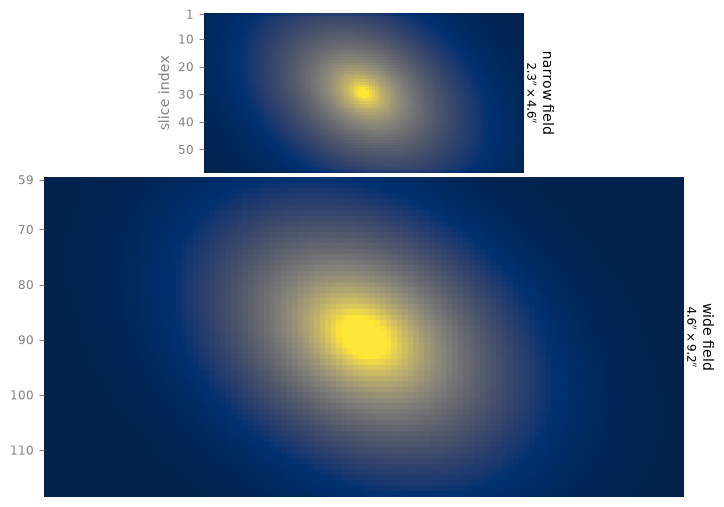

In [3]:
(cube_narrow, _), (cube_wide, _) = galaxy.get_cube(which="both", switch_off=SKY)
fig = galaxy.show_cube((cube_narrow, cube_wide), lbda_range=[6000, 9000])

Any default can be changed when building the galaxy, e.g. a real galaxy,
NGC 0628, moved to z=0.5 and placed lower in the narrow field so that the
wide field sees more of it:

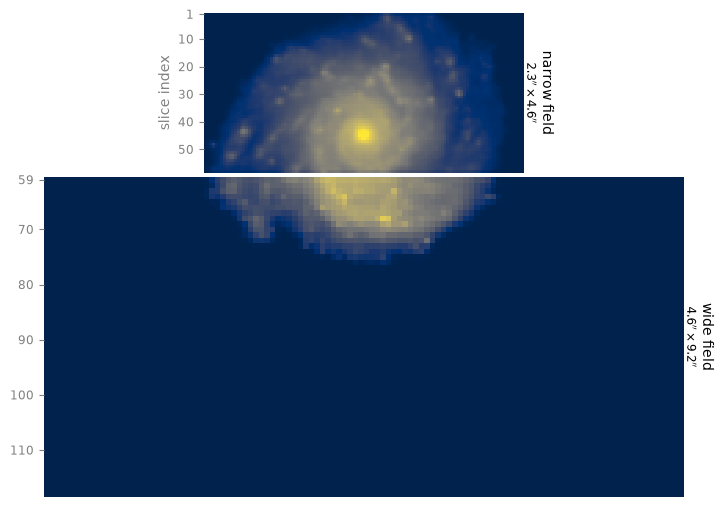

In [4]:
ngc = slicersim.LazuliGalaxy(redshift=0.5, model="ngc0628", position=(0, -15))

(cube_narrow, _), (cube_wide, _) = ngc.get_cube(which="both", switch_off=SKY)
fig = ngc.show_cube((cube_narrow, cube_wide), lbda_range=[6000, 9000])

## 2. Changing the galaxy properties

There is no point source, so the galaxy parameters can be changed directly
by their names (`host__` + name also works).

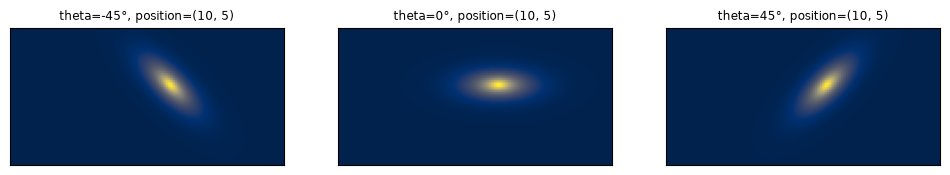

In [5]:
galaxy = slicersim.LazuliGalaxy(redshift=0.5, model="sersic:bb-6000",
                                r_kpc=3, n=1, ellip=0.6)

fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, theta in zip(axes, [-45, 0, 45]):
    galaxy.change_properties(theta=theta, position=(10, 5))
    cube, _ = galaxy.get_cube(which="narrow", switch_off=SKY)
    ax.imshow(cube.sum(axis=0), origin="lower", cmap="cividis")
    ax.set_title(f"theta={theta}°, position=(10, 5)", fontsize="small")
    ax.set_xticks([]); ax.set_yticks([])
plt.show()

**Redshift.** The galaxy keeps its physical size and its rest-frame
luminosity: as the redshift increases, it gets smaller and fainter, and
its spectrum moves to the red. Below, the narrow field is summed over
rest-frame 5000-6000 Å, with the same linear colour scale for the three
redshifts.

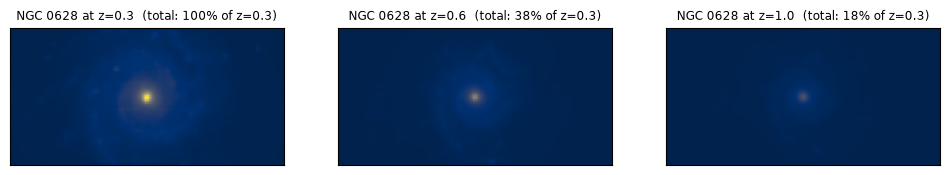

In [6]:
ngc = slicersim.LazuliGalaxy(redshift=0.3, model="ngc0628")
redshifts = [0.3, 0.6, 1.0]

images = []
for z in redshifts:
    ngc.change_properties(redshift=z)
    cube, _ = ngc.get_cube(which="narrow", switch_off=SKY)
    lbda = ngc.simulation.spectrograph.lbda
    restframe = (lbda > 5000 * (1 + z)) & (lbda < 6000 * (1 + z))
    images.append(cube[restframe].sum(axis=0))

fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, z, image in zip(axes, redshifts, images):
    ax.imshow(image, origin="lower", cmap="cividis", vmin=0, vmax=np.max(images[0]))
    ax.set_title(f"NGC 0628 at z={z}  (total: {image.sum() / images[0].sum():.0%} of z=0.3)",
                 fontsize="small")
    ax.set_xticks([]); ax.set_yticks([])
plt.show()

## 3. Spectrum and exposure time

The spectrum of a galaxy is extracted within an **aperture**, set by
`aperture`:

| `aperture` | extraction |
|---|---|
| `"core"` | the galaxy core, extracted as a point source would be (PSF-weighted) |
| `"<n>-arcsec"`, e.g. `"1-arcsec"` | aperture photometry within a radius of n arcsec [default: `"1-arcsec"`] |
| `"<n>-kpc"`, e.g. `"2-kpc"` | aperture photometry within a radius of n kpc, at the galaxy redshift |

The aperture is centered on the galaxy (`aperture__position="host"`, the
default), or anywhere else with `aperture__position=(x, y)`, in spaxels of
the current field. Both can be given when building the galaxy, or changed
with `change_properties`.

The signal is the galaxy light within the aperture (the sky is assumed
subtracted), and the variance includes every noise source within the
aperture: sky, galaxy, detector.

In [7]:
ngc = slicersim.LazuliGalaxy(redshift=0.5, model="ngc0628")
ngc.get_properties(["aperture", "aperture__position"])

{'aperture': '1-arcsec', 'aperture__position': 'host'}

`simulation.get_aperture()` returns the actual aperture: its center and
radius in spaxels, and whether it is PSF-weighted. Let us compare a few
apertures, for the same exposure:

{'nmd': (64, 8, 0), 'nramps': 4} exposure time: 97 min


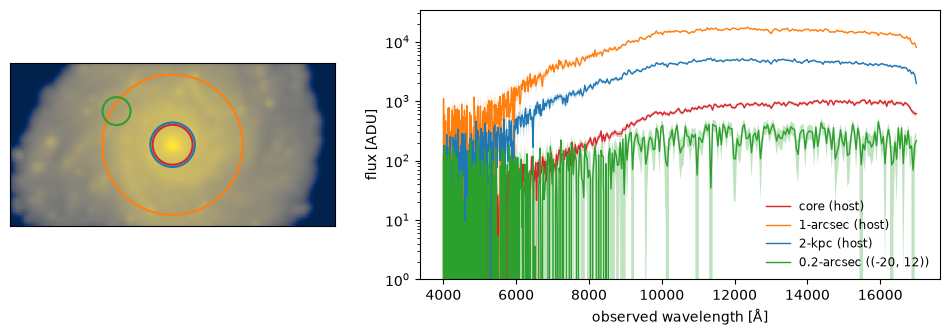

In [8]:
ngc.change_detector(nmd=(64, 8, 0), nramps=4)
print(ngc.get_readout_config(), f"exposure time: {ngc.get_exposure_time() / 60:.0f} min")

apertures = {"core": "host", "1-arcsec": "host", "2-kpc": "host",
             "0.2-arcsec": (-20, 12)}   # a region in the outskirts

cube, _ = ngc.get_cube(which="narrow", switch_off=SKY)
fig, (ax_im, ax_spec) = plt.subplots(1, 2, figsize=(12, 3.5),
                                     gridspec_kw={"width_ratios": [1, 1.6]})
ax_im.imshow(cube.sum(axis=0), origin="lower", cmap="cividis", norm="asinh")

ny, nx = cube.shape[1:]
for (aperture, position), color in zip(apertures.items(), ["C3", "C1", "C0", "C2"]):
    ngc.change_properties(aperture=aperture, aperture__position=position)
    (x, y), radius, _ = ngc.simulation.get_aperture()
    ax_im.add_patch(plt.Circle(((nx - 1) / 2 + x, (ny - 1) / 2 + y), radius,
                               fill=False, color=color, lw=1.5))

    lbda, flux, variance = ngc.get_spectrum()
    ax_spec.plot(lbda, flux, color=color, lw=1, label=f"{aperture} ({position})")
    ax_spec.fill_between(lbda, flux - np.sqrt(variance), flux + np.sqrt(variance),
                         color=color, alpha=0.3, lw=0)

ax_im.set_xticks([]); ax_im.set_yticks([])
ax_spec.set(xlabel="observed wavelength [Å]", ylabel="flux [ADU]", yscale="log", ylim=(1, None))
ax_spec.legend(frameon=False, fontsize="small")
plt.show()

A kpc aperture keeps the same physical size whatever the redshift, while
an arcsec aperture keeps the same angular size:

In [9]:
ngc.change_properties(aperture__position="host")
for z in [0.3, 0.6, 1.0]:
    ngc.change_properties(redshift=z)
    radii = {aperture: ngc.simulation.get_aperture(aperture)[1] * 0.04  # narrow field: 0.04 arcsec spaxels
             for aperture in ["1-arcsec", "2-kpc"]}
    print(f"z={z}: " + ", ".join(f"{k} radius = {v:.2f} arcsec" for k, v in radii.items()))

z=0.3: 1-arcsec radius = 1.00 arcsec, 2-kpc radius = 0.44 arcsec
z=0.6: 1-arcsec radius = 1.00 arcsec, 2-kpc radius = 0.29 arcsec
z=1.0: 1-arcsec radius = 1.00 arcsec, 2-kpc radius = 0.24 arcsec


As for any Lazuli target, `setup_to_snr` finds the read-out mode reaching
a signal-to-noise, here within 2 kpc of the galaxy center:

In [10]:
ngc = slicersim.LazuliGalaxy(redshift=0.5, model="ngc0628", aperture="2-kpc")
config, snr = ngc.setup_to_snr(10)
print(config, f"snr={snr:.1f}", f"exposure time: {ngc.get_exposure_time() / 60:.0f} min")

{'nmd': (64, 8, 0), 'nramps': 1} snr=9.3 exposure time: 24 min


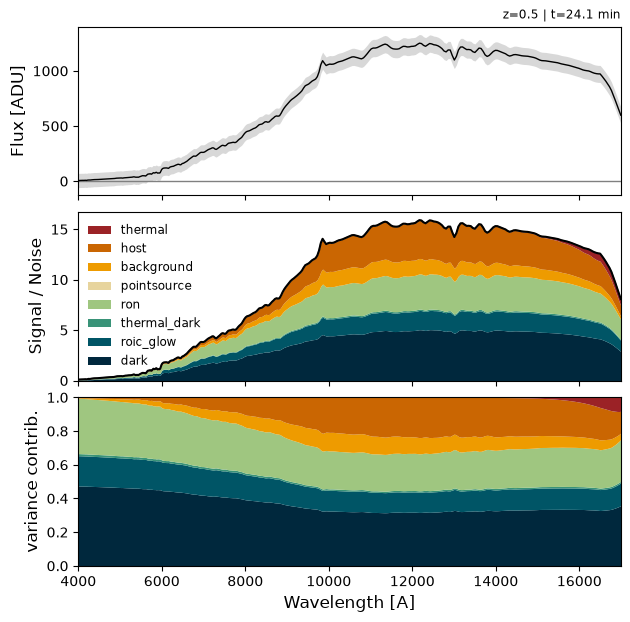

In [11]:
fig = ngc.simulation.show_variance_sources(flux_calibrated=False)

## 4. Galaxy alone or host?

`LazuliGalaxy(redshift, model=...)` and
`LazuliSupernova(redshift, host=...)` use the same galaxy model and
parameters. The supernova adds a point source on top of the galaxy, and
`get_spectrum` (and so `setup_to_snr`...) then returns the supernova
spectrum, the galaxy being a source of noise.

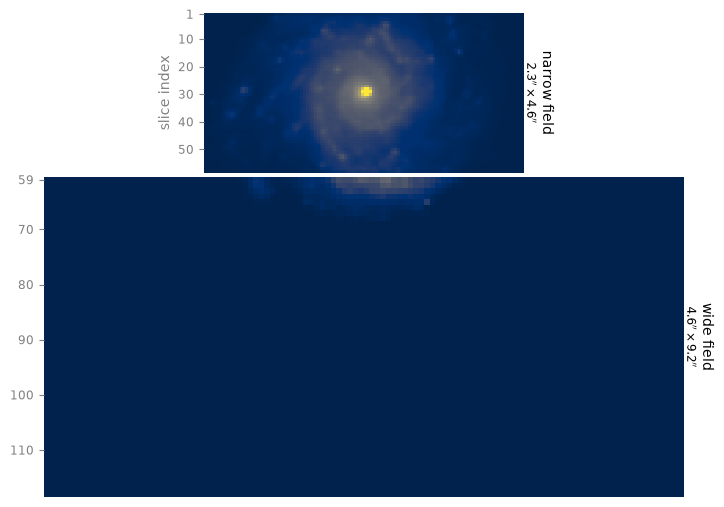

In [12]:
sn = slicersim.LazuliSupernova(redshift=0.5, host="ngc0628")
(cube_narrow, _), (cube_wide, _) = sn.get_cube(which="both", switch_off=SKY)
fig = sn.show_cube((cube_narrow, cube_wide), lbda_range=[6000, 9000])